<a href="https://colab.research.google.com/github/Cmay487/Premier_League_Match_Prediction/blob/UpdatedWorkbook_0308/ApplyingProbabilityToFootball.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📄 Notes on the Data


---

## ⚽ Key to Results Data

| Column | Description |
|--------|-------------|
| **Div** | League Division |
| **Date** | Match Date (dd/mm/yy) |
| **Time** | Time of match kick-off |
| **HomeTeam** | Home Team |
| **AwayTeam** | Away Team |
| **FTHG / HG** | Full Time Home Team Goals |
| **FTAG / AG** | Full Time Away Team Goals |
| **FTR / Res** | Full Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |
| **HTHG** | Half Time Home Team Goals |
| **HTAG** | Half Time Away Team Goals |
| **HTR** | Half Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |

---

## 📊 Match Statistics (where available)

| Column | Description |
|--------|-------------|
| **Attendance** | Crowd Attendance |
| **Referee** | Match Referee |
| **HS / AS** | Home / Away Shots |
| **HST / AST** | Home / Away Shots on Target |
| **HHW / AHW** | Home / Away Hit Woodwork |
| **HC / AC** | Home / Away Corners |
| **HF / AF** | Home / Away Fouls Committed |
| **HFKC / AFKC** | Home / Away Free Kicks Conceded |
| **HO / AO** | Home / Away Offsides |
| **HY / AY** | Home / Away Yellow Cards |
| **HR / AR** | Home / Away Red Cards |
| **HBP / ABP** | Home / Away Bookings Points (10 = yellow, 25 = red) |

> **Note 1:** Free Kicks Conceded includes fouls, offsides, and any other offence committed, and will always be equal to or higher than the number of fouls.  
> **Note 2:** English and Scottish yellow cards do not include the initial yellow when a second is shown that becomes a red (European games include it).

---

## 💰 Betting Odds Data (Pre-Closing Odds)

### Bookmaker Codes

| Code | Description |
|------|-------------|
| **B365H / B365D / B365A** | Bet365 home/draw/away odds |


# 📄 Section Notes
---



# Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

# funcs
from utils.get_data import extractWebData
from utils.probability import ProbabilityModelling
from utils.plotting import *
from utils.analysis import *
from utils.feature_engineering import *

# standard libraries for EDA
import scipy.stats as stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    binom, beta, poisson, expon, geom, nbinom,
    chi2_contingency
)

# web scraping
from bs4 import BeautifulSoup
import requests

# machine learning
from catboost import CatBoostClassifier, Pool
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score


# cross validation for time series
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# cross validation scoring
from sklearn.model_selection import cross_val_score

# ML Preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# pca
from sklearn.decomposition import PCA

# feature selection
from sklearn.feature_selection import RFE

# set sns theme
sns.set_theme(style="whitegrid", palette="pastel")



<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

In [22]:
# import train, val and test datasets
x_train = pd.read_csv('data/x_train.csv',parse_dates=True)
x_val = pd.read_csv('data/x_val.csv',parse_dates=True)
x_test = pd.read_csv('data/x_test.csv',parse_dates=True)

# import targets
y_train = pd.read_csv('data/y_train.csv')
y_val = pd.read_csv('data/y_val.csv')
y_test = pd.read_csv('data/y_test.csv')


print(x_train.shape)

(1900, 101)


In [23]:
# convert date time
x_train['Date'] = pd.to_datetime(x_train['Date'])
x_val['Date'] = pd.to_datetime(x_val['Date'])
x_test['Date'] = pd.to_datetime(x_test['Date'])

In [24]:
x_train.columns.to_list()

['Date',
 'Time',
 'HomeTeam',
 'AwayTeam',
 'FT_HomeGoals',
 'FT_AwayGoals',
 'FT_Result',
 'HT_HomeGoals',
 'HT_AwayGoals',
 'HT_Result',
 'Match Referee',
 'HomeShots',
 'AwayShots',
 'HomeShotsonTarget',
 'AwayShotsonTarget',
 'HomeFoulsCommitted',
 'AwayFoulsCommitted',
 'HomeCorners',
 'AwayCorners',
 'HomeYellowCards',
 'AwayYellowCards',
 'HomeRedCards',
 'AwayRedCards',
 'B365H',
 'B365D',
 'B365A',
 'MaxH',
 'MaxD',
 'MaxA',
 'AvgH',
 'AvgD',
 'AvgA',
 'Max>2.5',
 'Max<2.5',
 'Avg>2.5',
 'Avg<2.5',
 'B365AHH',
 'B365AHA',
 'MaxAHH',
 'MaxAHA',
 'AvgAHH',
 'AvgAHA',
 'B365CH',
 'B365CD',
 'B365CA',
 'MaxCH',
 'MaxCD',
 'MaxCA',
 'AvgCH',
 'AvgCD',
 'AvgCA',
 'B365C>2.5',
 'B365C<2.5',
 'MaxC>2.5',
 'MaxC<2.5',
 'AvgC>2.5',
 'AvgC<2.5',
 'AHCh',
 'AvgCAHH',
 'AvgCAHA',
 'Season',
 'DayofWeek',
 'Month',
 'Year',
 'SeasonOfYear',
 'HomeTeamHomeWinPct',
 'HomeTeamAwayWinPct',
 'HomeTeamDrawPct',
 'AwayTeamHomeWinPct',
 'AwayTeamAwayWinPct',
 'AwayTeamDrawPct',
 'HomeTeam5MatchSho

# Data Transformation

In [25]:
# drop any features we don't need or features that will invoke leakage
features_to_drop = [
    'HomeTeam',
    'AwayTeam',
    'Match Referee',
    'Season',
    'FT_Result',
    'HT_Result',
    'FT_HomeGoals',
    'FT_AwayGoals',
    'HT_HomeGoals',
    'HT_AwayGoals',
    'HomeShots',
    'AwayShots',
    'HomeShotsonTarget',
    'AwayShotsonTarget',
    'HomeFoulsCommitted',
    'AwayFoulsCommitted',
    'HomeCorners',
    'AwayCorners',
    'HomeYellowCards',
    'AwayYellowCards',
    'HomeRedCards',
    'AwayRedCards',
    'Time'
]

# drop the feature list
x_train.drop(columns=features_to_drop,inplace=True)
x_val.drop(columns=features_to_drop,inplace=True)
x_test.drop(columns=features_to_drop,inplace=True)

In [26]:
x_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1900 entries, 0 to 1899
Data columns (total 78 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Date                                     1900 non-null   datetime64[us]
 1   B365H                                    1900 non-null   float64       
 2   B365D                                    1900 non-null   float64       
 3   B365A                                    1900 non-null   float64       
 4   MaxH                                     1900 non-null   float64       
 5   MaxD                                     1900 non-null   float64       
 6   MaxA                                     1900 non-null   float64       
 7   AvgH                                     1900 non-null   float64       
 8   AvgD                                     1900 non-null   float64       
 9   AvgA                                     1900 non-nu

In [27]:
"""
Here I will create a data transformation pipeline to ready the data for modelling
"""
def data_prep_pipeline(in_df:pd.DataFrame):

  """
  For this function, I will use standard scaler for floats, min max scaler for ints
  and one hot encoder for obj data types
  """

  # build pipelines
  num_pipe = Pipeline([
        ('sc',StandardScaler())
    ])
  pct_pipe = Pipeline([
        ('mm', MinMaxScaler())
    ])
  cat_pipe = Pipeline([
        ('ohe',OneHotEncoder())
    ])


  #num_column = in_df.select_dtypes(include=[]).columns.tolist()
  int_col = in_df.select_dtypes(include=['int64','int32','float64']).columns.tolist()
  cat_column = in_df.select_dtypes(exclude=['float64','int64','int32']).columns.to_list()
  #cat_column.remove('Season')
  # join the two pipes together
  preprocessor = ColumnTransformer([
        #('num',num_pipe,num_column),
        ('cat',cat_pipe,cat_column),
        ('int',pct_pipe,int_col)
    ],remainder='passthrough')

  return preprocessor


In [28]:
processor = data_prep_pipeline(in_df=x_train)

# fit the data
x_train_processed = processor.fit_transform(x_train)
x_val_processed = processor.transform(x_val)
x_test_processed = processor.transform(x_test)

# get feature names
feature_names = processor.get_feature_names_out()

# convert to df
x_train_processed = pd.DataFrame(x_train_processed,columns=feature_names)

ValueError: Found unknown categories [np.datetime64('2025-03-10T00:00:00.000000'), np.datetime64('2024-09-21T00:00:00.000000'), np.datetime64('2025-04-05T00:00:00.000000'), np.datetime64('2025-02-23T00:00:00.000000'), np.datetime64('2024-12-29T00:00:00.000000'), np.datetime64('2024-12-22T00:00:00.000000'), np.datetime64('2025-04-01T00:00:00.000000'), np.datetime64('2024-09-22T00:00:00.000000'), np.datetime64('2025-04-14T00:00:00.000000'), np.datetime64('2025-04-21T00:00:00.000000'), np.datetime64('2024-09-30T00:00:00.000000'), np.datetime64('2024-11-24T00:00:00.000000'), np.datetime64('2024-11-29T00:00:00.000000'), np.datetime64('2024-09-15T00:00:00.000000'), np.datetime64('2025-04-27T00:00:00.000000'), np.datetime64('2024-09-28T00:00:00.000000'), np.datetime64('2024-12-21T00:00:00.000000'), np.datetime64('2024-09-01T00:00:00.000000'), np.datetime64('2025-01-05T00:00:00.000000'), np.datetime64('2025-02-25T00:00:00.000000'), np.datetime64('2025-05-10T00:00:00.000000'), np.datetime64('20

In [91]:
# transfor target
map_dict = {
    'H':2,
    'D':1,
    'A':0
}

y_train = y_train.map(map_dict)
y_val = y_val.map(map_dict)
y_test = y_test.map(map_dict)

### PCA

In [ ]:
"""
Because we have a significant amlunt of features, I will use PCA to reduce them down!
"""

'\nBecause we have a significant amlunt of features, I will use PCA to reduce them down!\n'

# Modelling

## Base model

In [93]:
"""
For this part, I just want to see what features are important, while understadning how well a
base model does with the data we have so far.

First I will run cross validation for time series
then i will fit my data to see what features are important
"""
dt = DecisionTreeClassifier(random_state=42)

models = {
    "Decision Tree": dt
}

run_cross_validation(x_train_processed,y_train,models)

AttributeError: 'csr_matrix' object has no attribute 'iloc'

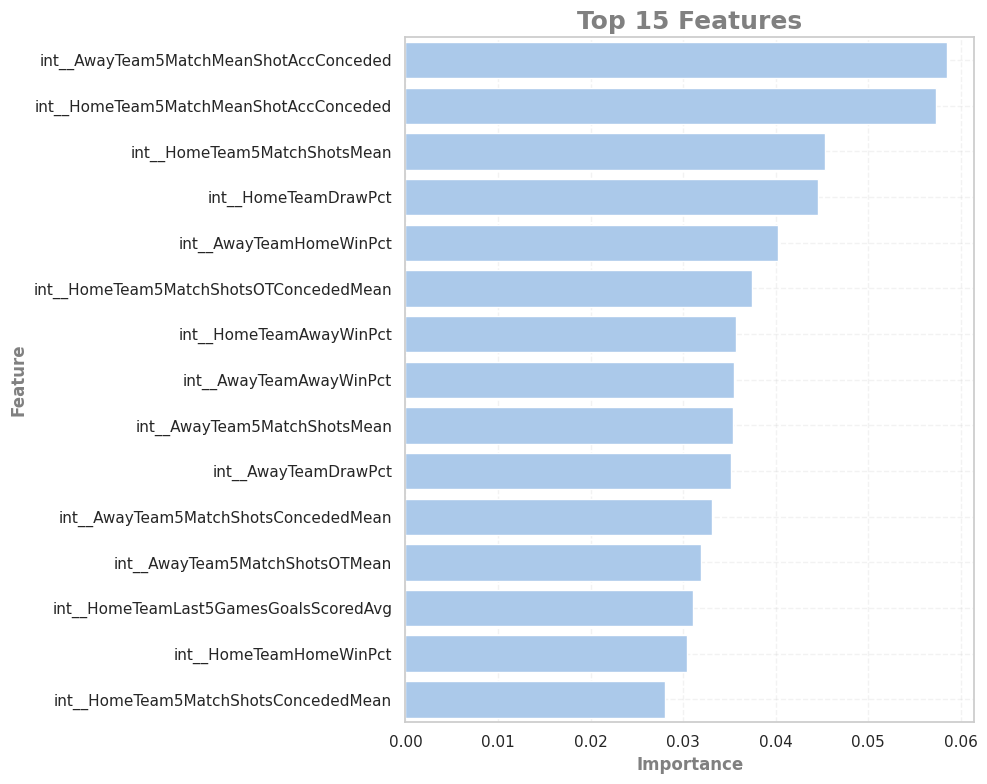

In [ ]:
"""
What are the best features?
"""

dt.fit(x_train_processed,y_train)

# show the top best features
feature_importance = dt.feature_importances_
feature_names_ = list(feature_names)

importance_df = (
    pd.DataFrame(
        list(zip(feature_names_,feature_importance)),
        columns=['Feature','Importance'])
)

top15Features = importance_df.sort_values(by='Importance',ascending=False).head(15)

# show results
plt.figure(
    figsize=(10,8)
)

sns.barplot(
    data=top15Features,
    y='Feature',
    x='Importance'
)

# adjust the visual
adjust_visuals(
    'Top 15 Features',
    'Importance',
    'Feature'
)

**Notes**

The base model that we have created is not very good, but provides some key insights:

1. The likely reason for such bad performance is due to the complexity of the dataset -> high bias caused by too many features.
2. The model appears to favour, although not considerably against the other features, the most recent features -> the last 5 games. Does this mean that teams are influenced by most recent results and form?
3. the Feature importance is fairly spread out where there is no single feature that holds the highest weight, which means there is little chance of data leakage!

I will reduce the complexity of the data by applying PCA and see what happens with our base model.

Before PCA: (2280, 79)
After PCA: (2280, 33)


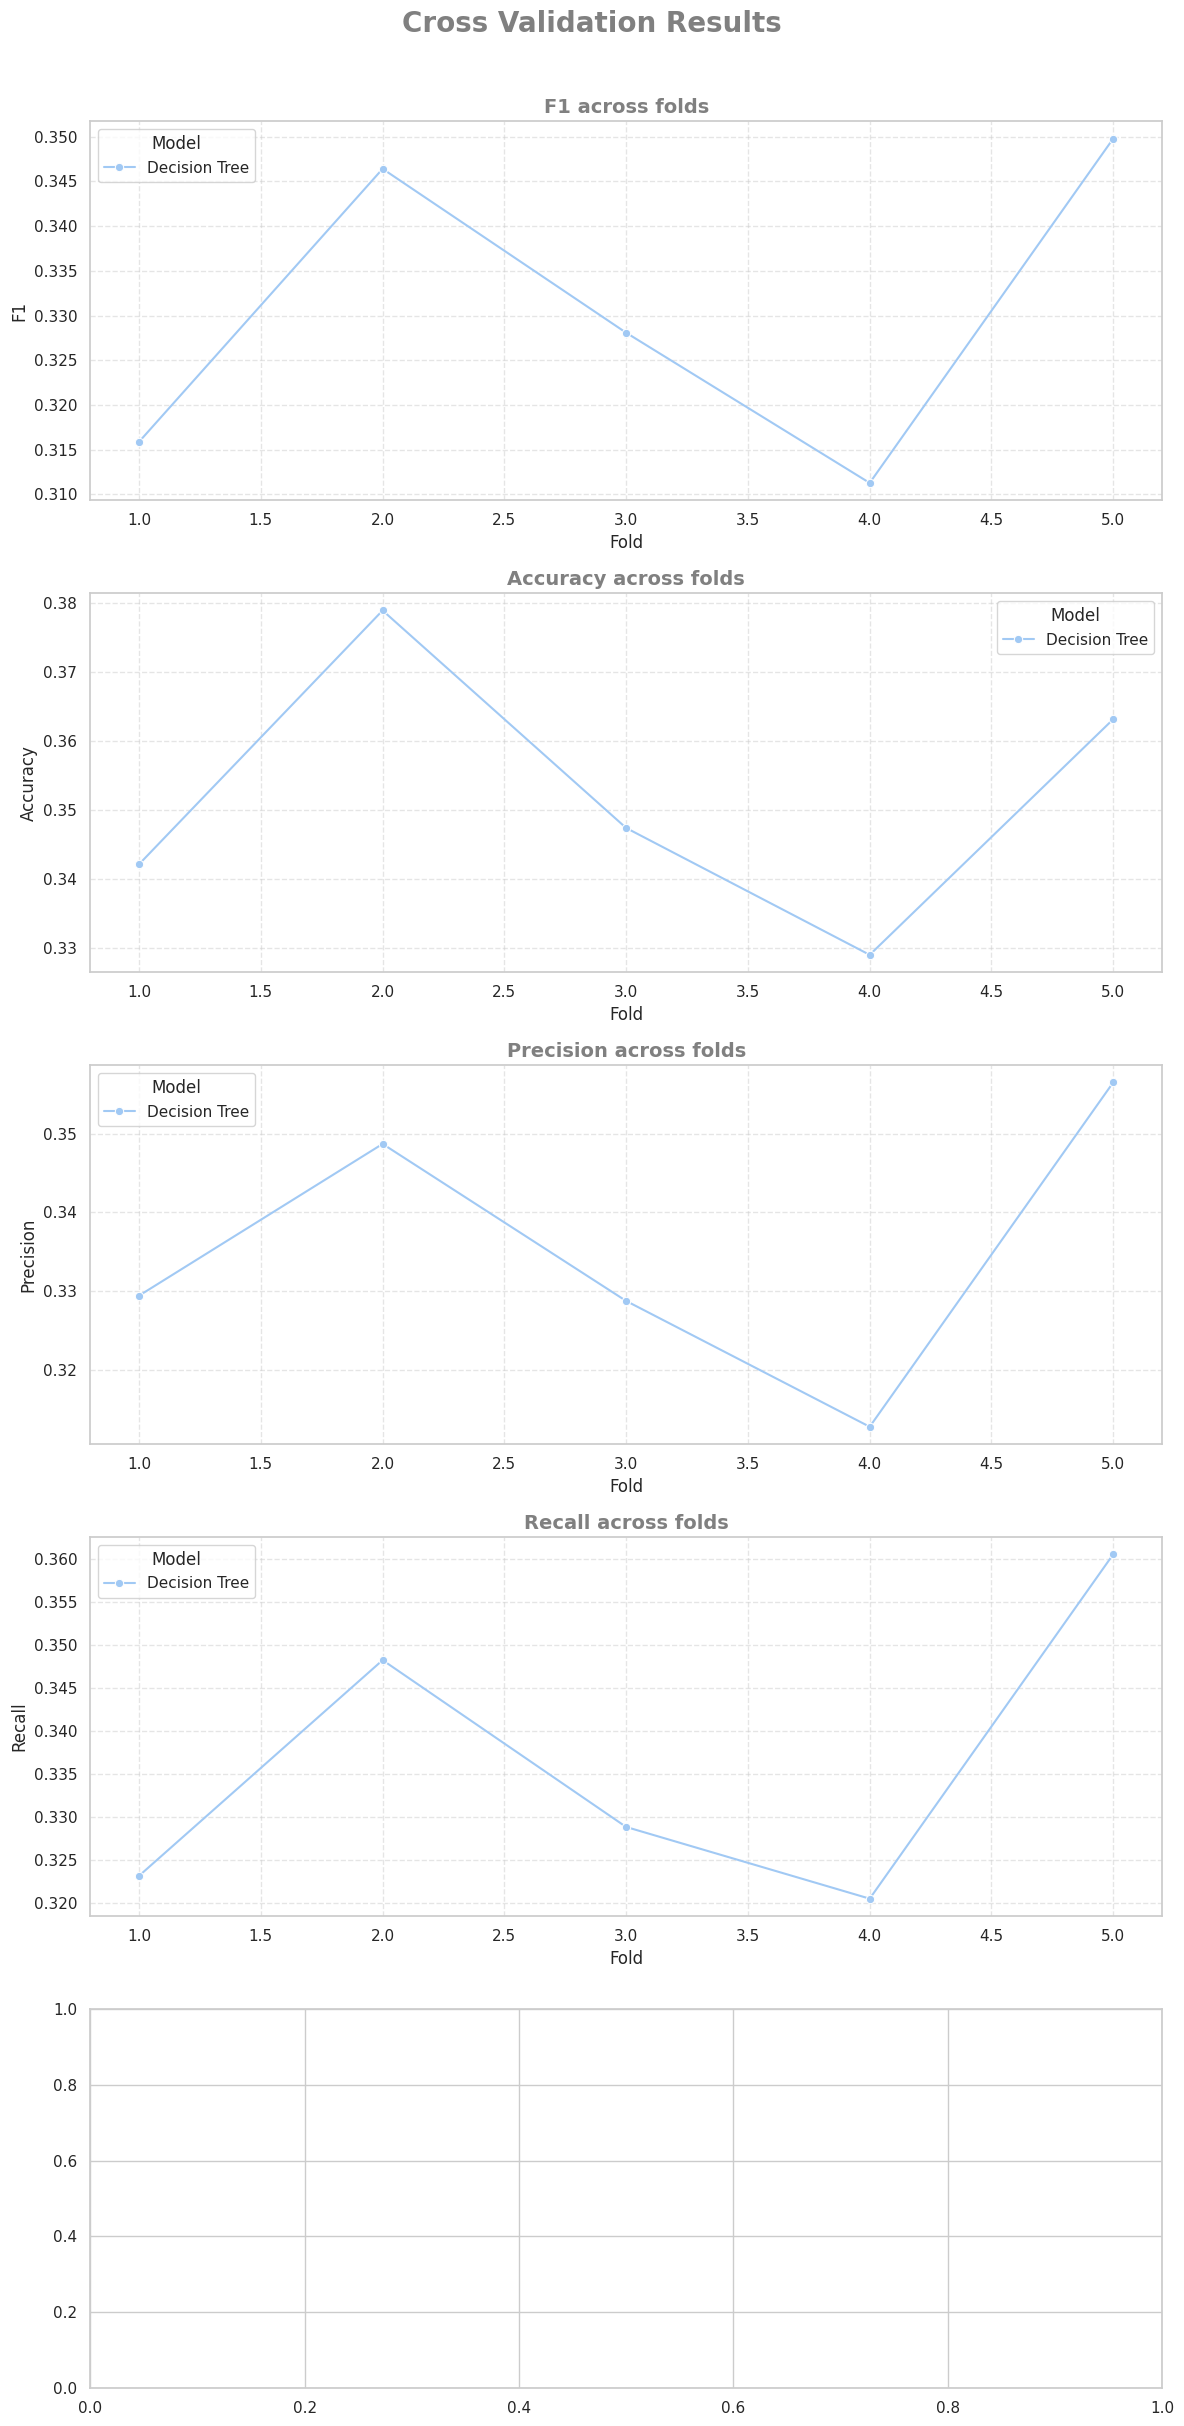

In [ ]:
# lets keep 95% of the information
pca = PCA(n_components=0.95)
pca.fit(x_train_processed)
x_train_pca = pca.transform(x_train_processed)

# now lets see the result
print(f"Before PCA: {x_train_processed.shape}")
print(f"After PCA: {x_train_pca.shape}")

# convert the x_train_pca to df
cols = [i for i in range(1,x_train_pca.shape[1]+1)]
x_train_pca_ = pd.DataFrame(x_train_pca,columns=cols)

run_cross_validation(x_train_pca_,y_train,models)

              precision    recall  f1-score   support

           0       0.32      0.28      0.30       132
           1       0.22      0.22      0.22        93
           2       0.42      0.46      0.44       155

    accuracy                           0.34       380
   macro avg       0.32      0.32      0.32       380
weighted avg       0.33      0.34      0.34       380



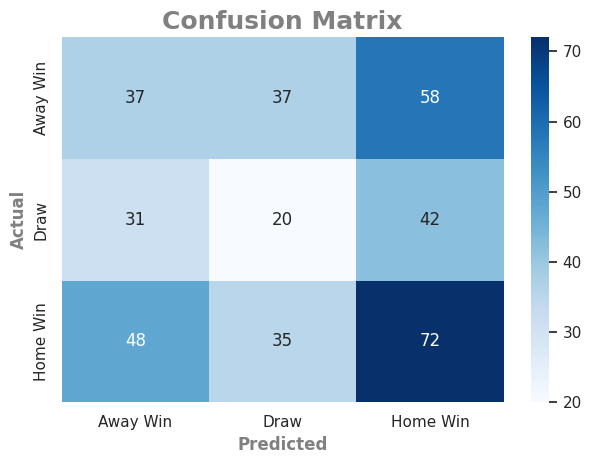

In [ ]:
# lets see where our base model is going wrong by using the validation as our
# "test" set.

dt.fit(x_train_processed,y_train)
y_pred = dt.predict(x_val_processed)

# compare with actual
print(classification_report(y_val,y_pred))

# print confusion matrix
target_labels = ['Away Win','Draw','Home Win']
mtx = confusion_matrix(y_val,y_pred)
sns.heatmap(
    mtx,
    annot=True,
    fmt='g',
    cmap='Blues',
    xticklabels=target_labels,
    yticklabels=target_labels
);




#adjust viz
adjust_visuals(
    'Confusion Matrix',
    'Predicted',
    'Actual'

)
